# IS353 - Lab 6a: Link Prediction và Sign Prediction

**MSSV:** 23520588

Đồ thị chính là Zachary Karate Club (34 đỉnh, 78 cạnh). Giấu khoảng 15% cạnh làm cặp test dương, lấy cùng số cặp không có cạnh làm cặp test âm, rồi chấm điểm từng cặp bằng 13 heuristic:

- **10 local:** CN, Jaccard, Adamic-Adar, Preferential Attachment, Salton, Sørensen, HPI, HDI, LHN1, Resource Allocation.
- **3 global:** Katz, Personalized PageRank (đối xứng hóa), Hitting time.

Đánh giá bằng ROC-AUC, Average Precision và Precision@k. Sau đó làm sign prediction trên một đồ thị có dấu nhỏ bằng logistic regression, cuối cùng chạy lại phần link prediction trên ego-Facebook.

So với notebook mẫu, có ba chỗ sửa:

1. Cặp âm lấy từ các cặp không có cạnh của **đồ thị đầy đủ**. Notebook mẫu lấy từ đồ thị train, nên có thể bốc trúng chính cạnh vừa giấu và gán nhãn 0 cho nó.
2. Khi giấu cạnh, bỏ qua cạnh nào mà xóa đi sẽ làm đồ thị đứt (ví dụ đỉnh 11 chỉ có một cạnh). Hitting time chỉ có nghĩa trên đồ thị liên thông.
3. Ở sign prediction, feature của cặp test chỉ tính từ các cạnh train, để dấu của cạnh test không lọt vào feature của nhau.

## Cài thư viện

In [1]:
%pip install -q networkx numpy scipy pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: D:\Study\IS353\BT\.venv\Scripts\python.exe -m pip install --upgrade pip


## Import

In [2]:
%matplotlib inline

import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import numpy.linalg as LA
import pandas as pd
import scipy.sparse.linalg as spla
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score,
    precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.grid": True,
})
pd.set_option("display.precision", 3)

## Hàm dùng chung

- `holdout_split`: giấu một tỉ lệ cạnh, giữ đồ thị train liên thông.
- `sample_negatives`: lấy ngẫu nhiên cặp không có cạnh trong đồ thị đầy đủ.
- `eval_binary_scores`: AUC, AP, Precision@k.

In [3]:
def lab_dir() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd() / "BT" / "Lab6a",
        Path(r"d:/Study/IS353/BT/Lab6a"),
    ]
    for folder in candidates:
        if (folder / "requirement.txt").exists() and "Lab6a" in str(folder):
            return folder
    raise FileNotFoundError("Không thấy requirement.txt của Lab 6a.")


LAB = lab_dir()
FIG = LAB / "figures"
FIG.mkdir(exist_ok=True)


def holdout_split(G_full, frac, rng, keep_connected=True):
    # Xóa lần lượt từng cạnh; nếu xóa xong u và v không còn đường đi thì trả cạnh lại.
    G = G_full.copy()
    edges = list(G_full.edges())
    rng.shuffle(edges)
    n_hold = max(1, int(frac * len(edges)))
    test_pos = []
    for u, v in edges:
        if len(test_pos) == n_hold:
            break
        G.remove_edge(u, v)
        if keep_connected and not nx.has_path(G, u, v):
            G.add_edge(u, v)
            continue
        test_pos.append((u, v))
    return G, test_pos


def sample_negatives(G_full, n, rng):
    nodes = list(G_full.nodes())
    seen = set()
    out = []
    while len(out) < n:
        u, v = rng.sample(nodes, 2)
        key = (min(u, v), max(u, v))
        if key in seen or G_full.has_edge(u, v):
            continue
        seen.add(key)
        out.append(key)
    return out


def precision_at_k(y_true, y_score, k):
    order = np.argsort(y_score, kind="stable")[::-1]
    y_sorted = np.asarray(y_true)[order]
    k = min(k, len(y_sorted))
    return float(np.sum(y_sorted[:k])) / float(k) if k > 0 else 0.0


def eval_binary_scores(y_true, y_score, ks=(5, 10, 20)):
    out = {
        "AUC": roc_auc_score(y_true, y_score),
        "AP": average_precision_score(y_true, y_score),
    }
    for k in ks:
        out[f"P@{k}"] = precision_at_k(y_true, y_score, k)
    return out


def plot_roc_pr(y_true, y_score, title_prefix="", fname=None):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, y_score):.3f}")
    axes[0].plot([0, 1], [0, 1], linestyle="--", color="#999999")
    axes[0].set_xlabel("FPR")
    axes[0].set_ylabel("TPR")
    axes[0].set_title(f"{title_prefix} ROC")
    axes[0].legend(loc="lower right")
    axes[1].plot(recall, precision, label=f"AP = {average_precision_score(y_true, y_score):.3f}")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title(f"{title_prefix} Precision-Recall")
    axes[1].legend(loc="lower left")
    fig.tight_layout()
    if fname:
        fig.savefig(FIG / fname, bbox_inches="tight")
    plt.show()

## Karate Club và tập test

Giấu 15% cạnh (11 cạnh) làm cặp dương, lấy 11 cặp không có cạnh làm cặp âm. Cạnh bị giấu vẽ nét đứt màu đỏ.

Train edges: 67, test positives: 11, test negatives: 11
connected train graph: True
held-out edges: [(14, 33), (15, 32), (19, 33), (0, 10), (18, 33), (27, 33), (3, 12), (0, 31), (23, 33), (20, 32), (26, 33)]
negative pairs: [(10, 15), (10, 29), (17, 24), (14, 20), (3, 14), (2, 20), (17, 25), (4, 13), (13, 20), (9, 29), (8, 16)]


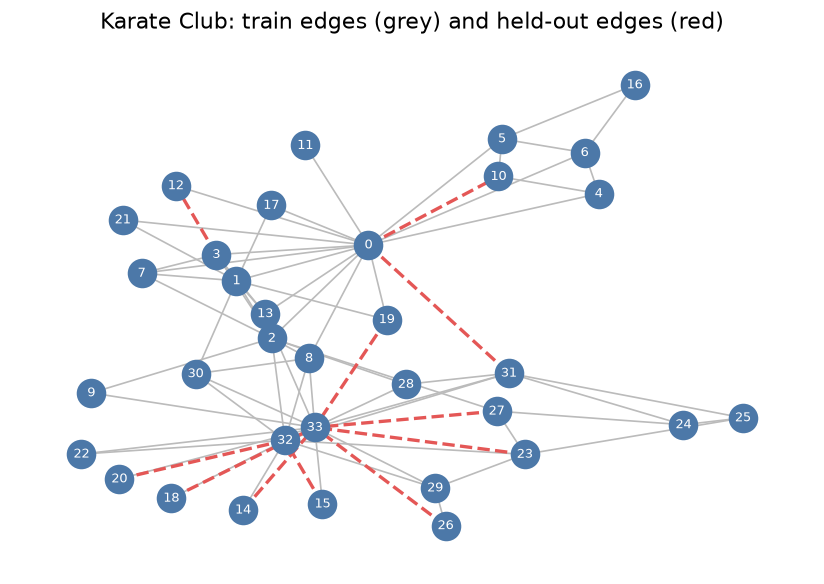

In [4]:
G_full = nx.karate_club_graph()
for u, v in G_full.edges():
    G_full[u][v].pop("weight", None)  # dùng đồ thị không trọng số

rng = random.Random(42)
G, E_test_pos = holdout_split(G_full, 0.15, rng)
E_test_neg = sample_negatives(G_full, len(E_test_pos), rng)
E_test = [(u, v, 1) for u, v in E_test_pos] + [(u, v, 0) for u, v in E_test_neg]

print(f"Train edges: {G.number_of_edges()}, test positives: {len(E_test_pos)}, test negatives: {len(E_test_neg)}")
print("connected train graph:", nx.is_connected(G))
print("held-out edges:", E_test_pos)
print("negative pairs:", E_test_neg)

pos = nx.spring_layout(G_full, seed=42)
fig, ax = plt.subplots(figsize=(7, 5))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#bbbbbb")
nx.draw_networkx_edges(G_full, pos, edgelist=E_test_pos, ax=ax, edge_color="#E45756", style="--", width=2)
nx.draw_networkx_nodes(G_full, pos, ax=ax, node_size=280, node_color="#4C78A8")
nx.draw_networkx_labels(G_full, pos, ax=ax, font_size=8, font_color="white")
ax.set_title("Karate Club: train edges (grey) and held-out edges (red)")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "karate_holdout.png", bbox_inches="tight")
plt.show()

## 10 heuristic local

Ký hiệu $\Gamma(x)$ là tập hàng xóm của $x$, $k_x$ là bậc.

| Heuristic | Công thức |
| --- | --- |
| CN | $\lvert\Gamma(x)\cap\Gamma(y)\rvert$ |
| Jaccard | $\lvert\Gamma(x)\cap\Gamma(y)\rvert / \lvert\Gamma(x)\cup\Gamma(y)\rvert$ |
| Adamic-Adar | $\sum_{z\in\Gamma(x)\cap\Gamma(y)} 1/\log k_z$ |
| Pref. Attachment | $k_x k_y$ |
| Salton | $CN / \sqrt{k_x k_y}$ |
| Sørensen | $2\,CN / (k_x + k_y)$ |
| HPI | $CN / \min(k_x, k_y)$ |
| HDI | $CN / \max(k_x, k_y)$ |
| LHN1 | $CN / (k_x k_y)$ |
| Resource Allocation | $\sum_{z\in\Gamma(x)\cap\Gamma(y)} 1/k_z$ |

In [5]:
def CN(G, x, y):
    return len(set(G[x]) & set(G[y]))


def JC(G, x, y):
    nx_, ny_ = set(G[x]), set(G[y])
    uni = len(nx_ | ny_)
    return len(nx_ & ny_) / uni if uni else 0.0


def AA(G, x, y):
    return sum(1.0 / math.log(G.degree(z)) for z in set(G[x]) & set(G[y]) if G.degree(z) > 1)


def PA(G, x, y):
    return G.degree(x) * G.degree(y)


def Salton(G, x, y):
    d = math.sqrt(G.degree(x) * G.degree(y))
    return CN(G, x, y) / d if d else 0.0


def Sorensen(G, x, y):
    d = G.degree(x) + G.degree(y)
    return 2.0 * CN(G, x, y) / d if d else 0.0


def HPI(G, x, y):
    d = min(G.degree(x), G.degree(y))
    return CN(G, x, y) / d if d else 0.0


def HDI(G, x, y):
    d = max(G.degree(x), G.degree(y))
    return CN(G, x, y) / d if d else 0.0


def LHN1(G, x, y):
    d = G.degree(x) * G.degree(y)
    return CN(G, x, y) / d if d else 0.0


def RA(G, x, y):
    return sum(1.0 / G.degree(z) for z in set(G[x]) & set(G[y]) if G.degree(z) > 0)


LOCAL = {"CN": CN, "JC": JC, "AA": AA, "PA": PA, "Salton": Salton, "Sorensen": Sorensen,
         "HPI": HPI, "HDI": HDI, "LHN1": LHN1, "RA": RA}
LOCAL_KEYS = list(LOCAL)


def compute_local_scores(G, pairs):
    rows = []
    for u, v, y in pairs:
        row = {"u": u, "v": v, "y": y}
        for name, fn in LOCAL.items():
            row[name] = fn(G, u, v)
        rows.append(row)
    return pd.DataFrame(rows)


df_local = compute_local_scores(G, E_test)
print(df_local.shape)
df_local

(22, 13)


,u,v,y,CN,JC,AA,PA,Salton,Sorensen,HPI,HDI,LHN1,RA
0,14,33,1,1,0.091,0.434,11,0.302,0.167,1.000,0.091,0.091,0.100
1,15,32,1,1,0.100,0.417,10,0.316,0.182,1.000,0.100,0.100,0.091
2,19,33,1,0,0.000,0.000,22,0.000,0.000,0.000,0.000,0.000,0.000
3,0,10,1,2,0.143,1.632,28,0.378,0.250,1.000,0.143,0.071,0.583
4,18,33,1,1,0.091,0.434,11,0.302,0.167,1.000,0.091,0.091,0.100
5,27,33,1,0,0.000,0.000,33,0.000,0.000,0.000,0.000,0.000,0.000
6,3,12,1,1,0.200,0.379,5,0.447,0.333,1.000,0.200,0.200,0.071
7,0,31,1,0,0.000,0.000,70,0.000,0.000,0.000,0.000,0.000,0.000
8,23,33,1,2,0.154,1.156,44,0.302,0.267,0.500,0.182,0.045,0.350
9,20,32,1,1,0.100,0.417,10,0.316,0.182,1.000,0.100,0.100,0.091


## 3 heuristic global

**Katz.** Đếm mọi walk giữa hai đỉnh, walk dài $l$ nhân thêm $\beta^l$: $K = (I - \beta A)^{-1} - I$, cần $\beta < 1/\rho(A)$.

**Personalized PageRank.** $PPR_{u\to v}$ là xác suất dừng ở $v$ của random walk có teleport về $u$. Viết dạng ma trận: với $W = A D^{-1}$ (cột ngẫu nhiên), $\Pi = (1-\alpha)(I - \alpha W)^{-1}$ và $PPR_{u\to v} = \Pi_{vu}$. Một lần nghịch đảo cho đủ mọi cặp, thay vì gọi `nx.pagerank` cho từng cặp. Đối xứng hóa bằng $PPR_{u\to v} + PPR_{v\to u}$.

**Hitting time.** Với đồ thị vô hướng liên thông, $H_{i\to j} = \mathrm{vol}(G)\,(L^+_{jj} - L^+_{ij})$, $L^+$ là giả nghịch đảo của $L = D - A$. Đồ thị liên thông nên $L^+ = (L + J/n)^{-1} - J/n$ với $J$ là ma trận toàn 1, chỉ cần một phép nghịch đảo thường. Thời gian càng ngắn càng giống nhau, nên similarity là $-H_{u\to v}$ (notebook mẫu chuẩn hóa z-score rồi đổi dấu, thứ tự cặp không đổi nên AUC như nhau). Thêm một cột commute time $-(H_{u\to v} + H_{v\to u})$ để so.

In [6]:
def global_matrices(G, beta=None, alpha=0.85):
    nodes = sorted(G.nodes())
    idx = {n: i for i, n in enumerate(nodes)}
    A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
    n = A.shape[0]
    I = np.eye(n)
    deg = A.sum(axis=1)
    rho = float(spla.eigsh(A, k=1, which="LA", return_eigenvectors=False)[0]) if n > 50 else float(max(LA.eigvalsh(A)))
    if beta is None:
        beta = 0.5 / rho
    assert beta < 1.0 / rho, "beta phải nhỏ hơn 1/rho(A)"

    K = LA.inv(I - beta * A) - I
    W = A / deg[np.newaxis, :]
    Pi = (1 - alpha) * LA.inv(I - alpha * W)
    J = np.ones((n, n)) / n
    L = np.diag(deg) - A
    Lplus = LA.inv(L + J) - J
    vol = deg.sum()
    H = vol * (np.diag(Lplus)[np.newaxis, :] - Lplus)  # H[i, j] = vol * (L+_jj - L+_ij)
    return {"idx": idx, "K": K, "Pi": Pi, "H": H, "beta": beta, "rho": rho}


def add_global_scores(df, mats):
    idx, K, Pi, H = mats["idx"], mats["K"], mats["Pi"], mats["H"]
    i = df["u"].map(idx).values
    j = df["v"].map(idx).values
    df = df.copy()
    df["Katz"] = K[i, j] + K[j, i]
    df["PPR(u->v)"] = Pi[j, i]
    df["PPR(v->u)"] = Pi[i, j]
    df["PPR_sym"] = df["PPR(u->v)"] + df["PPR(v->u)"]
    df["HT_sim"] = -H[i, j]
    df["CT_sim"] = -(H[i, j] + H[j, i])
    return df


mats = global_matrices(G, beta=0.03)
print(f"rho(A) = {mats['rho']:.3f}, 1/rho = {1 / mats['rho']:.4f}, beta = {mats['beta']}")

# Kiểm tra PPR dạng ma trận khớp với nx.pagerank
u0, v0 = E_test[0][0], E_test[0][1]
pr = nx.pagerank(G, alpha=0.85, personalization={n: float(n == u0) for n in G}, tol=1e-12)
print(f"PPR({u0}->{v0}): matrix = {mats['Pi'][mats['idx'][v0], mats['idx'][u0]]:.6f}, nx.pagerank = {pr[v0]:.6f}")

df_all = add_global_scores(df_local, mats)
df_all[["u", "v", "y", "Katz", "PPR(u->v)", "PPR(v->u)", "PPR_sym", "HT_sim", "CT_sim"]]

rho(A) = 6.111, 1/rho = 0.1636, beta = 0.03
PPR(14->33): matrix = 0.081267, nx.pagerank = 0.081267


,u,v,y,Katz,PPR(u->v),PPR(v->u),PPR_sym,HT_sim,CT_sim
0,14,33,1,2.124e-03,0.081,0.007,0.089,-18.076,-164.580
1,15,32,1,2.124e-03,0.074,0.007,0.081,-20.386,-164.580
2,19,33,1,2.605e-04,0.034,0.006,0.040,-26.900,-110.481
3,0,10,1,3.776e-03,0.018,0.128,0.147,-107.833,-116.426
4,18,33,1,2.124e-03,0.081,0.007,0.089,-18.076,-164.580
5,27,33,1,4.832e-04,0.056,0.015,0.071,-19.360,-80.128
6,3,12,1,2.078e-03,0.008,0.038,0.045,-141.085,-173.377
7,0,31,1,3.324e-04,0.011,0.031,0.043,-50.740,-77.662
8,23,33,1,4.090e-03,0.070,0.026,0.096,-16.922,-65.054
9,20,32,1,2.124e-03,0.074,0.007,0.081,-20.386,-164.580


## Đánh giá trên một lần chia

Có 22 cặp test, nên P@20 gần như bằng tỉ lệ dương chung, chỉ P@5 và P@10 là có ý nghĩa.

,Heuristic,AUC,AP,P@5,P@10,P@20
0,PPR_sym,0.975,0.975,1.0,0.9,0.55
1,HT_sim,0.901,0.929,1.0,0.9,0.55
2,Katz,0.893,0.903,1.0,0.8,0.55
3,PA,0.876,0.887,1.0,0.8,0.55
4,CT_sim,0.818,0.840,0.8,0.8,0.55
5,AA,0.789,0.798,1.0,0.7,0.45
6,RA,0.789,0.798,1.0,0.7,0.45
7,HPI,0.785,0.766,0.8,0.8,0.45
8,CN,0.752,0.715,0.4,0.7,0.45
9,Salton,0.715,0.655,0.6,0.8,0.45


Tỉ lệ cặp có CN = 0: dương 0.27, âm 0.73


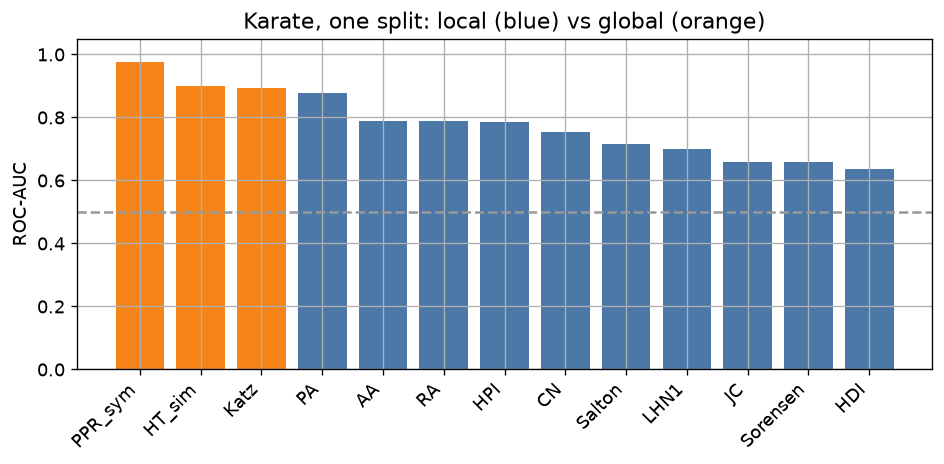

In [7]:
KEYS = LOCAL_KEYS + ["Katz", "PPR_sym", "HT_sim"]
EXTRA = ["CT_sim"]
y_true = df_all["y"].values

summary = []
for k in KEYS + EXTRA:
    row = {"Heuristic": k}
    row.update(eval_binary_scores(y_true, df_all[k].values, ks=(5, 10, 20)))
    summary.append(row)
df_eval = pd.DataFrame(summary).sort_values("AUC", ascending=False).reset_index(drop=True)
display(df_eval)

pos_cn0 = (df_all.loc[df_all.y == 1, "CN"] == 0).mean()
neg_cn0 = (df_all.loc[df_all.y == 0, "CN"] == 0).mean()
print(f"Tỉ lệ cặp có CN = 0: dương {pos_cn0:.2f}, âm {neg_cn0:.2f}")

plot_df = df_eval[df_eval.Heuristic.isin(KEYS)]
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#F58518" if h in ("Katz", "PPR_sym", "HT_sim") else "#4C78A8" for h in plot_df.Heuristic]
ax.bar(plot_df.Heuristic, plot_df.AUC, color=colors)
ax.axhline(0.5, color="#999999", linestyle="--")
ax.set_ylim(0, 1.05)
ax.set_ylabel("ROC-AUC")
ax.set_title("Karate, one split: local (blue) vs global (orange)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(FIG / "karate_auc_bar.png", bbox_inches="tight")
plt.show()

Top-3 by AUC: ['PPR_sym', 'HT_sim', 'Katz']


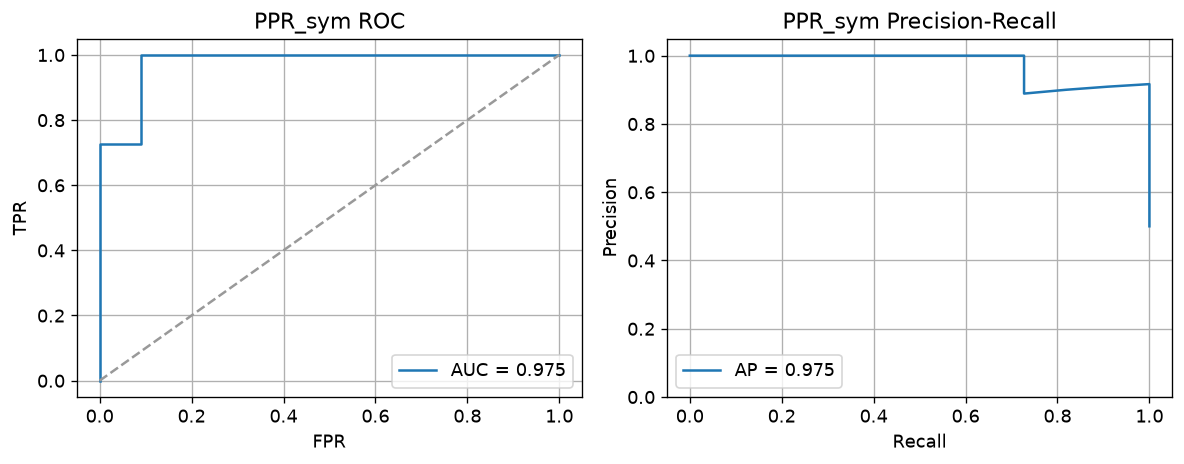

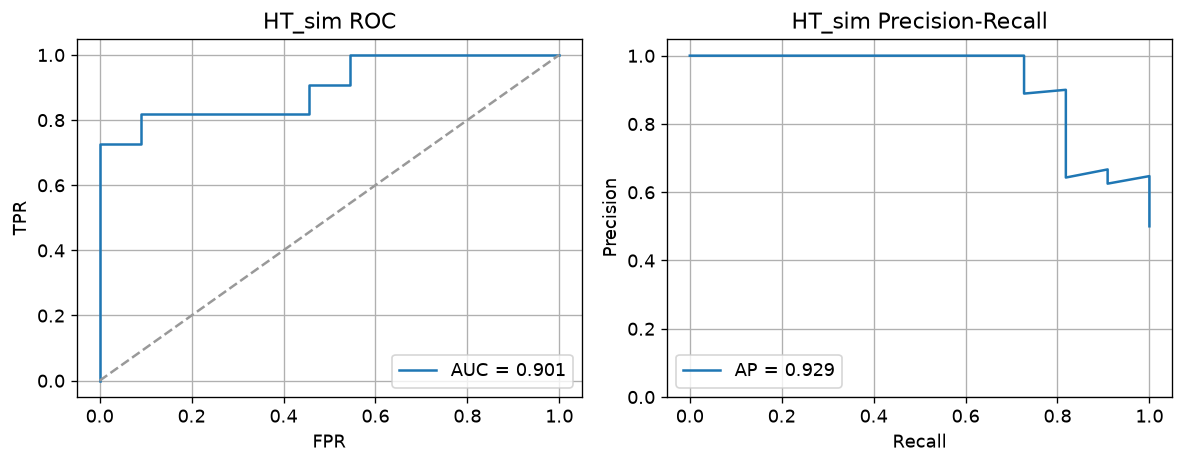

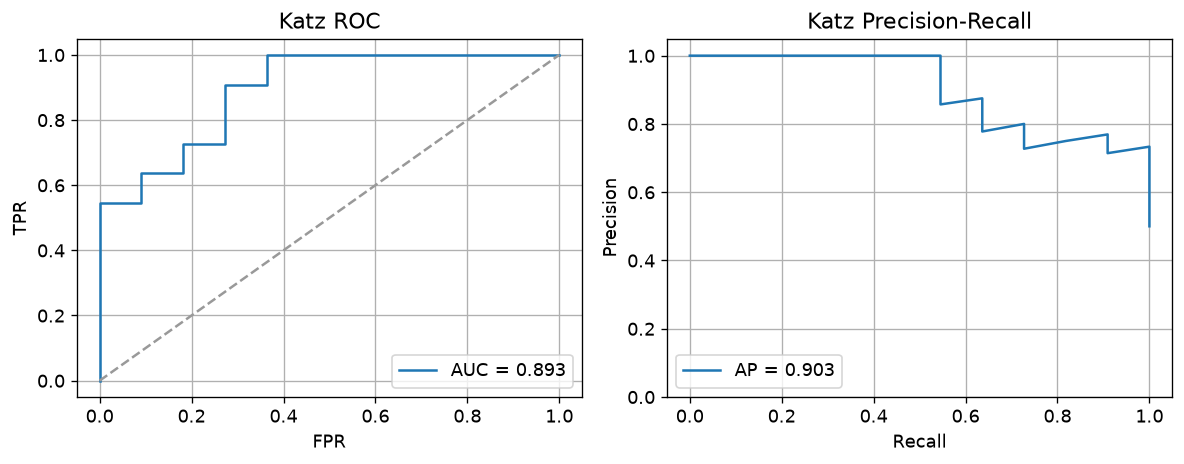

In [8]:
top3 = df_eval[df_eval.Heuristic.isin(KEYS)].head(3)["Heuristic"].tolist()
print("Top-3 by AUC:", top3)
for k in top3:
    plot_roc_pr(y_true, df_all[k].values, title_prefix=k, fname=f"karate_roc_pr_{k}.png")

## Lặp lại trên 30 lần chia

Một lần chia chỉ có 11 cặp dương, đổi seed là thứ hạng đổi. Chạy 30 lần chia khác nhau, lấy trung bình và độ lệch chuẩn của AUC, AP, rồi đếm số lần RA thắng, hòa, thua AA.

,Heuristic,AUC mean,AUC std,AP mean,AP std,P@10 mean
0,PPR_sym,0.878,0.066,0.886,0.071,0.837
1,Katz,0.766,0.085,0.782,0.078,0.707
2,RA,0.747,0.075,0.764,0.072,0.697
3,PA,0.740,0.068,0.747,0.081,0.683
4,AA,0.737,0.077,0.750,0.069,0.690
5,HT_sim,0.708,0.111,0.776,0.093,0.687
6,CN,0.699,0.079,0.690,0.066,0.530
7,HPI,0.699,0.094,0.666,0.090,0.677
8,CT_sim,0.681,0.087,0.734,0.094,0.637
9,Salton,0.644,0.099,0.623,0.094,0.633


RA vs AA (AUC): thắng 17, hòa 11, thua 2
Salton   vs CN (AUC): thắng  6, hòa  1, thua 23
Sorensen vs CN (AUC): thắng  1, hòa  0, thua 29
JC       vs CN (AUC): thắng  1, hòa  0, thua 29
HPI      vs CN (AUC): thắng 18, hòa  0, thua 12
HDI      vs CN (AUC): thắng  1, hòa  0, thua 29
LHN1     vs CN (AUC): thắng  3, hòa  1, thua 26


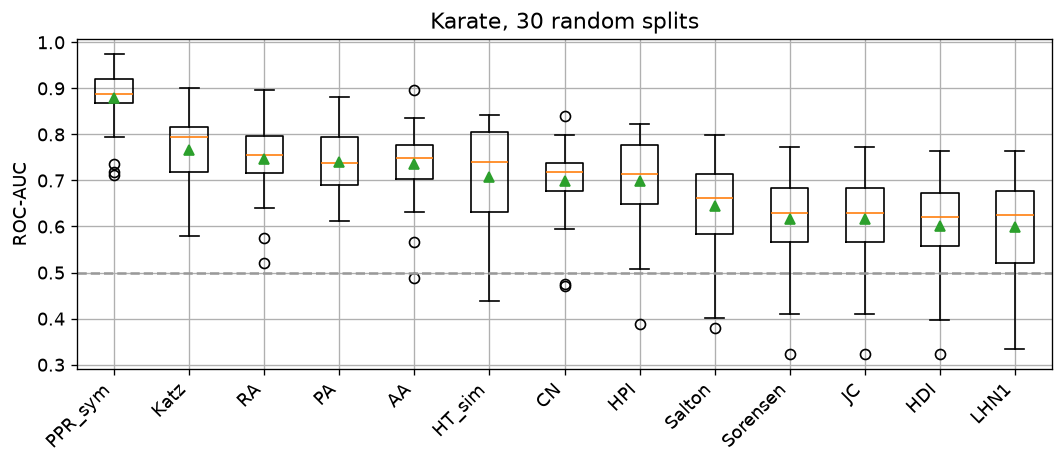

In [9]:
def run_split(G_full, seed, frac=0.15, beta=0.03):
    rng = random.Random(seed)
    Gtr, pos_e = holdout_split(G_full, frac, rng)
    neg_e = sample_negatives(G_full, len(pos_e), rng)
    pairs = [(u, v, 1) for u, v in pos_e] + [(u, v, 0) for u, v in neg_e]
    df = add_global_scores(compute_local_scores(Gtr, pairs), global_matrices(Gtr, beta=beta))
    y = df["y"].values
    return {k: eval_binary_scores(y, df[k].values, ks=(5, 10)) for k in KEYS + EXTRA}


SEEDS = range(30)
runs = [run_split(G_full, s) for s in SEEDS]
rep = []
for k in KEYS + EXTRA:
    auc = np.array([r[k]["AUC"] for r in runs])
    ap = np.array([r[k]["AP"] for r in runs])
    p10 = np.array([r[k]["P@10"] for r in runs])
    rep.append({"Heuristic": k, "AUC mean": auc.mean(), "AUC std": auc.std(),
                "AP mean": ap.mean(), "AP std": ap.std(), "P@10 mean": p10.mean()})
df_rep = pd.DataFrame(rep).sort_values("AUC mean", ascending=False).reset_index(drop=True)
display(df_rep)

ra = np.array([r["RA"]["AUC"] for r in runs])
aa = np.array([r["AA"]["AUC"] for r in runs])
cn = np.array([r["CN"]["AUC"] for r in runs])
print(f"RA vs AA (AUC): thắng {np.sum(ra > aa + 1e-12)}, hòa {np.sum(np.isclose(ra, aa))}, thua {np.sum(ra < aa - 1e-12)}")
for k in ("Salton", "Sorensen", "JC", "HPI", "HDI", "LHN1"):
    other = np.array([r[k]["AUC"] for r in runs])
    print(f"{k:8s} vs CN (AUC): thắng {np.sum(other > cn + 1e-12):2d}, hòa {np.sum(np.isclose(other, cn)):2d}, thua {np.sum(other < cn - 1e-12):2d}")

order = df_rep[df_rep.Heuristic.isin(KEYS)]["Heuristic"].tolist()
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([[r[k]["AUC"] for r in runs] for k in order], showmeans=True)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.axhline(0.5, color="#999999", linestyle="--")
ax.set_ylabel("ROC-AUC")
ax.set_title("Karate, 30 random splits")
fig.tight_layout()
fig.savefig(FIG / "karate_auc_box.png", bbox_inches="tight")
plt.show()

### Katz theo β

Với Karate, $1/\rho(A) \approx 0.149$. β nhỏ thì Katz gần với đếm walk độ dài 2 (tức CN), β lớn thì walk dài có trọng số lớn hơn.

In [10]:
for beta in (0.005, 0.03, 0.08, 0.13):
    aucs = [run_split(G_full, s, beta=beta)["Katz"]["AUC"] for s in SEEDS]
    print(f"beta={beta:<6} Katz AUC = {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")

beta=0.005  Katz AUC = 0.766 ± 0.086


beta=0.03   Katz AUC = 0.766 ± 0.085


beta=0.08   Katz AUC = 0.763 ± 0.085


beta=0.13   Katz AUC = 0.763 ± 0.084


## Sign prediction trên đồ thị có dấu nhỏ

Ba cụm thân thiện (cạnh +, màu xanh), vài cạnh đối địch giữa các cụm (cạnh −, màu đỏ). Feature của cặp $(u, v)$ là số hàng xóm chung theo bốn kiểu dấu $(s_{uz}, s_{vz})$: ++, +−, −+, −−, cộng tổng số hàng xóm chung. Logistic regression dự đoán dấu (+1 là lớp 1).

Signed graph: 12 nodes, 21 edges (15 +, 6 -)


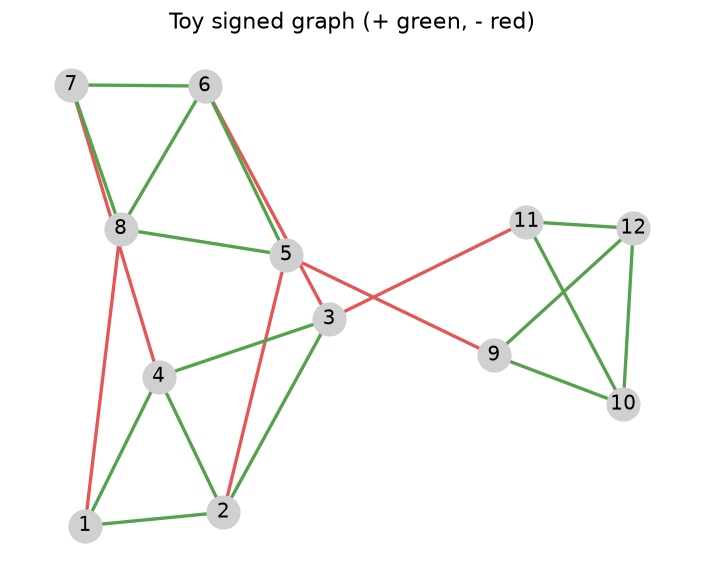

In [11]:
SG = nx.Graph()
SG.add_nodes_from(range(1, 13))
pos_edges = [(1, 2), (2, 3), (3, 4), (4, 1), (2, 4),
             (5, 6), (6, 7), (7, 8), (8, 5), (6, 8),
             (9, 10), (10, 11), (11, 12), (12, 9), (10, 12)]
neg_edges = [(3, 6), (4, 7), (1, 8), (2, 5), (9, 5), (11, 3)]
for u, v in pos_edges:
    SG.add_edge(u, v, sign=+1)
for u, v in neg_edges:
    SG.add_edge(u, v, sign=-1)
print("Signed graph:", SG.number_of_nodes(), "nodes,", SG.number_of_edges(), "edges",
      f"({len(pos_edges)} +, {len(neg_edges)} -)")

pos_s = nx.spring_layout(SG, seed=7)
fig, ax = plt.subplots(figsize=(6, 5))
edge_colors = ["#54A24B" if SG[u][v]["sign"] > 0 else "#E45756" for u, v in SG.edges()]
nx.draw(SG, pos_s, ax=ax, with_labels=True, node_size=380, node_color="#d0d0d0",
        edge_color=edge_colors, width=2)
ax.set_title("Toy signed graph (+ green, - red)")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "signed_toy.png", bbox_inches="tight")
plt.show()

train 14 edges, test 7 edges (2 negative)
LogReg   accuracy=0.714  F1=0.833  AUC=0.800
Balance  accuracy=0.714  F1=0.833
Feature weights: {'pp': 0.767, 'pm': 0.0, 'mp': 0.0, 'mm': 0.0, 'CN': 0.767}


,edge,pp,pm,mp,mm,CN,sign,P(+)
0,"(4, 7)",0,0,0,0,0,-1,0.596
1,"(10, 11)",1,0,0,0,1,1,0.872
2,"(2, 3)",0,0,0,0,0,1,0.596
3,"(5, 8)",1,0,0,0,1,1,0.872
4,"(3, 4)",0,0,0,0,0,1,0.596
5,"(7, 8)",1,0,0,0,1,1,0.872
6,"(3, 11)",0,0,0,0,0,-1,0.596


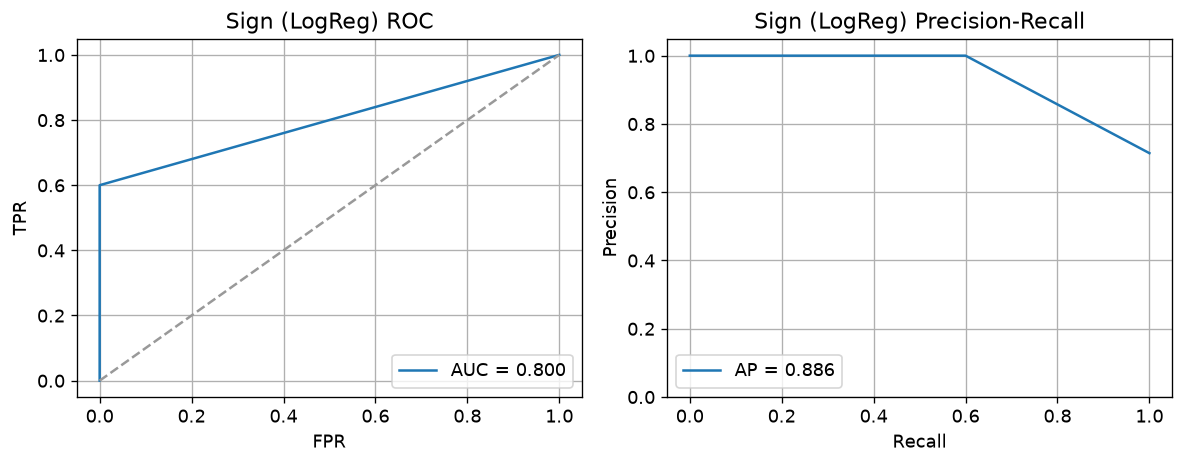

In [12]:
FEAT = ["pp", "pm", "mp", "mm", "CN"]


def signed_cn_features(SGtr, u, v):
    pp = pm = mp = mm = 0
    cn = set(SGtr[u]) & set(SGtr[v]) if u in SGtr and v in SGtr else set()
    for z in cn:
        s_uz, s_vz = SGtr[u][z]["sign"], SGtr[v][z]["sign"]
        if s_uz > 0 and s_vz > 0:
            pp += 1
        elif s_uz > 0 and s_vz < 0:
            pm += 1
        elif s_uz < 0 and s_vz > 0:
            mp += 1
        else:
            mm += 1
    return [pp, pm, mp, mm, len(cn)]


def edges_to_xy(SGtr, edges):
    X = np.array([signed_cn_features(SGtr, u, v) for u, v, _ in edges], dtype=float)
    y = np.array([1 if d["sign"] > 0 else 0 for _, _, d in edges])
    return X, y


def balance_predict(X):
    # Lý thuyết cân bằng: tam giác ++ hoặc -- ủng hộ cạnh +, tam giác +- / -+ ủng hộ cạnh -.
    # Không có hàng xóm chung thì đoán + (lớp đa số).
    vote = X[:, 0] + X[:, 3] - X[:, 1] - X[:, 2]
    return (vote >= 0).astype(int)


all_edges = list(SG.edges(data=True))
signs = [d["sign"] for _, _, d in all_edges]
train_edges, test_edges = train_test_split(all_edges, test_size=0.3, random_state=42, stratify=signs)
SG_train = nx.Graph()
SG_train.add_nodes_from(SG.nodes())
SG_train.add_edges_from(train_edges)

Xtr, ytr = edges_to_xy(SG_train, train_edges)
Xte, yte = edges_to_xy(SG_train, test_edges)
clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
yp = clf.predict(Xte)
proba = clf.predict_proba(Xte)[:, 1]

print(f"train {len(train_edges)} edges, test {len(test_edges)} edges ({int((yte == 0).sum())} negative)")
print(f"LogReg   accuracy={accuracy_score(yte, yp):.3f}  F1={f1_score(yte, yp):.3f}  AUC={roc_auc_score(yte, proba):.3f}")
yb = balance_predict(Xte)
print(f"Balance  accuracy={accuracy_score(yte, yb):.3f}  F1={f1_score(yte, yb):.3f}")
print("Feature weights:", {k: round(float(w), 3) for k, w in zip(FEAT, clf.coef_[0])})

test_table = pd.DataFrame(Xte.astype(int), columns=FEAT)
test_table.insert(0, "edge", [(u, v) for u, v, _ in test_edges])
test_table["sign"] = [d["sign"] for _, _, d in test_edges]
test_table["P(+)"] = proba
display(test_table)

plot_roc_pr(yte, proba, title_prefix="Sign (LogReg)", fname="signed_toy_roc_pr.png")

Tập test chỉ có 7 cạnh. Để đỡ phụ thuộc may rủi, chạy thêm leave-one-out trên cả 21 cạnh: mỗi lần bỏ một cạnh ra làm test, train trên 20 cạnh còn lại (feature cũng tính trên 20 cạnh đó). Bảng feature của toàn bộ cạnh cho thấy vì sao mô hình tách được hai lớp.

In [13]:
loo_pred, loo_prob = [], []
for i, (u, v, d) in enumerate(all_edges):
    tr = all_edges[:i] + all_edges[i + 1:]
    SGi = nx.Graph()
    SGi.add_nodes_from(SG.nodes())
    SGi.add_edges_from(tr)
    Xi, yi = edges_to_xy(SGi, tr)
    xi, _ = edges_to_xy(SGi, [(u, v, d)])
    m = LogisticRegression(max_iter=1000).fit(Xi, yi)
    loo_pred.append(int(m.predict(xi)[0]))
    loo_prob.append(float(m.predict_proba(xi)[0, 1]))
y_all = np.array([1 if s > 0 else 0 for s in signs])
print(f"LOO accuracy={accuracy_score(y_all, loo_pred):.3f}  F1={f1_score(y_all, loo_pred):.3f}  AUC={roc_auc_score(y_all, loo_prob):.3f}")

X_all, _ = edges_to_xy(SG, all_edges)
feat_table = pd.DataFrame(X_all.astype(int), columns=FEAT)
feat_table.insert(0, "edge", [(u, v) for u, v, _ in all_edges])
feat_table["sign"] = signs
print("\nTrung bình feature theo dấu cạnh:")
display(feat_table.groupby("sign")[FEAT].mean())

LOO accuracy=1.000  F1=1.000  AUC=1.000

Trung bình feature theo dấu cạnh:


,pp,pm,mp,mm,CN
sign,,,,,
-1,0.0,0.0,0.0,0.0,0.0
1,1.2,0.0,0.0,0.0,1.2


## Thêm: đồ thị có dấu tổng hợp lớn hơn

Đồ thị nhỏ ở trên có cạnh − nào cũng là cầu nối giữa hai cụm, không nằm trong tam giác nào. Vì vậy chỉ cần biết "có hàng xóm chung hay không" là đủ, bốn kiểu dấu không có dịp thể hiện. Để thấy rõ vai trò của pp, pm, mp, mm, dựng một đồ thị có dấu ngẫu nhiên lớn hơn:

- 4 nhóm, mỗi nhóm 25 đỉnh. Trong nhóm nối với xác suất 0.30, giữa hai nhóm 0.08.
- Cạnh trong nhóm mang dấu +, cạnh giữa nhóm mang dấu −. Đảo dấu ngẫu nhiên 10% cạnh làm nhiễu.
- 70% cạnh train, 30% test, feature tính trên đồ thị train. Chuẩn hóa feature trước khi fit để so được độ lớn hệ số.

nodes=100, edges=687, positive share=0.56
LogReg   accuracy=0.729  F1=0.745  AUC=0.763
Balance  accuracy=0.633  F1=0.730
Majority accuracy=0.560
Standardized weights: {'pp': 1.158, 'pm': -0.625, 'mp': -0.61, 'mm': 0.28, 'CN': 0.535}

AUC khi chỉ dùng một feature / khi bỏ một feature:
  pp : only = 0.750, drop = 0.763
  pm : only = 0.565, drop = 0.765


  mp : only = 0.552, drop = 0.770
  mm : only = 0.518, drop = 0.765
  CN : only = 0.643, drop = 0.763


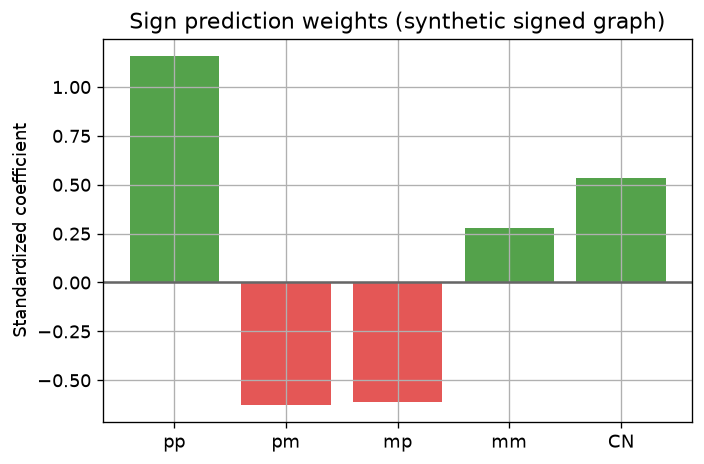

In [14]:
rng_s = np.random.default_rng(7)
groups = np.repeat(np.arange(4), 25)
SB = nx.Graph()
SB.add_nodes_from(range(len(groups)))
for i in range(len(groups)):
    for j in range(i + 1, len(groups)):
        same = groups[i] == groups[j]
        if rng_s.random() < (0.30 if same else 0.08):
            sign = 1 if same else -1
            if rng_s.random() < 0.10:
                sign = -sign
            SB.add_edge(i, j, sign=sign)
sb_edges = list(SB.edges(data=True))
sb_signs = [d["sign"] for _, _, d in sb_edges]
print(f"nodes={SB.number_of_nodes()}, edges={SB.number_of_edges()}, positive share={np.mean(np.array(sb_signs) > 0):.2f}")

tr_e, te_e = train_test_split(sb_edges, test_size=0.3, random_state=0, stratify=sb_signs)
SB_train = nx.Graph()
SB_train.add_nodes_from(SB.nodes())
SB_train.add_edges_from(tr_e)
Xtr_b, ytr_b = edges_to_xy(SB_train, tr_e)
Xte_b, yte_b = edges_to_xy(SB_train, te_e)
scaler = StandardScaler().fit(Xtr_b)
clf_b = LogisticRegression(max_iter=2000).fit(scaler.transform(Xtr_b), ytr_b)
proba_b = clf_b.predict_proba(scaler.transform(Xte_b))[:, 1]
yp_b = (proba_b >= 0.5).astype(int)
yb_b = balance_predict(Xte_b)
print(f"LogReg   accuracy={accuracy_score(yte_b, yp_b):.3f}  F1={f1_score(yte_b, yp_b):.3f}  AUC={roc_auc_score(yte_b, proba_b):.3f}")
print(f"Balance  accuracy={accuracy_score(yte_b, yb_b):.3f}  F1={f1_score(yte_b, yb_b):.3f}")
print(f"Majority accuracy={np.mean(yte_b == 1):.3f}")
print("Standardized weights:", {k: round(float(w), 3) for k, w in zip(FEAT, clf_b.coef_[0])})

# Bỏ từng feature, xem AUC giảm bao nhiêu
print("\nAUC khi chỉ dùng một feature / khi bỏ một feature:")
for i, name in enumerate(FEAT):
    keep = [j for j in range(len(FEAT)) if j != i]
    m1 = LogisticRegression(max_iter=2000).fit(Xtr_b[:, [i]], ytr_b)
    m2 = LogisticRegression(max_iter=2000).fit(Xtr_b[:, keep], ytr_b)
    auc1 = roc_auc_score(yte_b, m1.predict_proba(Xte_b[:, [i]])[:, 1])
    auc2 = roc_auc_score(yte_b, m2.predict_proba(Xte_b[:, keep])[:, 1])
    print(f"  {name:3s}: only = {auc1:.3f}, drop = {auc2:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(FEAT, clf_b.coef_[0], color=["#54A24B" if w > 0 else "#E45756" for w in clf_b.coef_[0]])
ax.axhline(0, color="#666666")
ax.set_ylabel("Standardized coefficient")
ax.set_title("Sign prediction weights (synthetic signed graph)")
fig.tight_layout()
fig.savefig(FIG / "signed_sbm_weights.png", bbox_inches="tight")
plt.show()

## Optional: ego-Facebook

4039 đỉnh, 88234 cạnh. Giấu 1% cạnh (882 cạnh), lấy 882 cặp âm. Với 4039 đỉnh, ma trận dày 4039 × 4039 chỉ khoảng 130 MB, nên vẫn tính chính xác Katz, PPR và hitting time bằng nghịch đảo ma trận. Đo thời gian từng phần để so chi phí. β của Katz đặt bằng $0.5/\rho(A)$.

In [15]:
fb_candidates = [
    LAB.parent / "Lab1_2" / "facebook_combined.txt",
    LAB / "facebook_combined.txt",
    Path.cwd() / "facebook_combined.txt",
]
fb_path = next(path for path in fb_candidates if path.exists())
print(f"Đọc {fb_path}")
Gbig = nx.read_edgelist(fb_path, nodetype=int)
print("Loaded:", Gbig.number_of_nodes(), "nodes,", Gbig.number_of_edges(), "edges")

rng_fb = random.Random(42)
t0 = time.perf_counter()
Gtrain, fb_pos = holdout_split(Gbig, 0.01, rng_fb)
fb_neg = sample_negatives(Gbig, len(fb_pos), rng_fb)
E_test_big = [(u, v, 1) for u, v in fb_pos] + [(u, v, 0) for u, v in fb_neg]
print(f"split: {len(fb_pos)} pos, {len(fb_neg)} neg, connected={nx.is_connected(Gtrain)}, {time.perf_counter() - t0:.1f}s")

timing = {}
t0 = time.perf_counter()
df_local_big = compute_local_scores(Gtrain, E_test_big)
timing["10 local (all pairs)"] = time.perf_counter() - t0

t0 = time.perf_counter()
mats_big = global_matrices(Gtrain, beta=None)
timing["Katz + PPR + HT matrices"] = time.perf_counter() - t0
df_big = add_global_scores(df_local_big, mats_big)
print(f"rho(A) = {mats_big['rho']:.2f}, beta = {mats_big['beta']:.5f}")

# Thời gian từng phương pháp global riêng lẻ
nodes_b = sorted(Gtrain.nodes())
A_b = nx.to_numpy_array(Gtrain, nodelist=nodes_b, weight=None)
I_b = np.eye(len(nodes_b))
t0 = time.perf_counter(); LA.inv(I_b - mats_big["beta"] * A_b); timing["Katz only"] = time.perf_counter() - t0
deg_b = A_b.sum(axis=1)
t0 = time.perf_counter(); LA.inv(I_b - 0.85 * A_b / deg_b[np.newaxis, :]); timing["PPR only"] = time.perf_counter() - t0
J_b = np.ones_like(A_b) / len(nodes_b)
t0 = time.perf_counter(); LA.inv(np.diag(deg_b) - A_b + J_b); timing["HT only (L+)"] = time.perf_counter() - t0
u1, v1 = fb_pos[0]
t0 = time.perf_counter()
nx.pagerank(Gtrain, alpha=0.85, personalization={u1: 1.0})
nx.pagerank(Gtrain, alpha=0.85, personalization={v1: 1.0})
timing["PPR_sym, 1 pair via nx.pagerank"] = time.perf_counter() - t0
del A_b, I_b, J_b

for k, v in timing.items():
    print(f"{k:34s} {v:7.2f} s")

Đọc d:\Study\IS353\BT\Lab1_2\facebook_combined.txt


Loaded: 4039 nodes, 88234 edges
split: 882 pos, 882 neg, connected=True, 0.2s


rho(A) = 160.75, beta = 0.00311


10 local (all pairs)                  0.28 s
Katz + PPR + HT matrices             12.82 s
Katz only                             3.86 s
PPR only                              3.29 s
HT only (L+)                          3.21 s
PPR_sym, 1 pair via nx.pagerank       0.24 s


,Heuristic,AUC,AP,P@10,P@50,P@100
0,RA,0.995,0.994,1.0,1.00,1.00
1,AA,0.994,0.990,1.0,1.00,1.00
2,CN,0.993,0.988,1.0,1.00,1.00
3,Salton,0.992,0.990,1.0,1.00,1.00
4,Katz,0.991,0.987,1.0,1.00,1.00
5,JC,0.990,0.988,1.0,1.00,1.00
6,Sorensen,0.990,0.988,1.0,1.00,1.00
7,PPR_sym,0.990,0.984,1.0,1.00,1.00
8,HPI,0.989,0.978,0.7,0.94,0.97
9,HDI,0.989,0.986,1.0,1.00,1.00


Tỉ lệ cặp có CN = 0: dương 0.000, âm 0.830


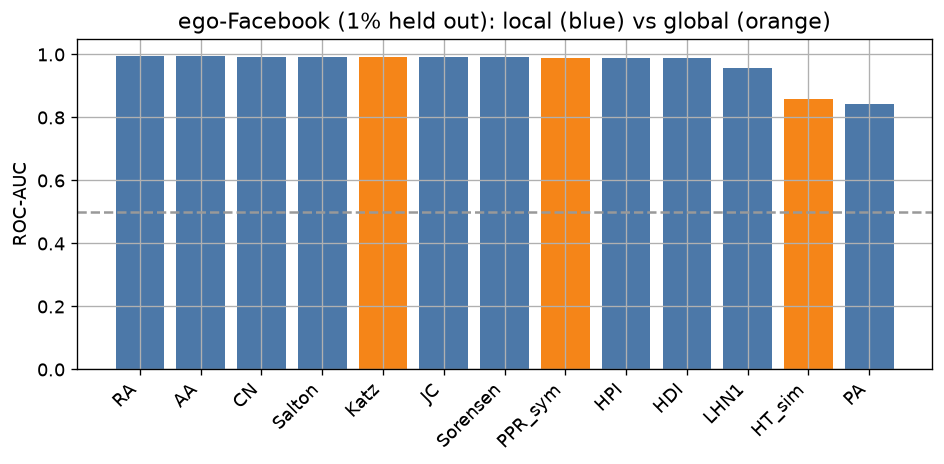

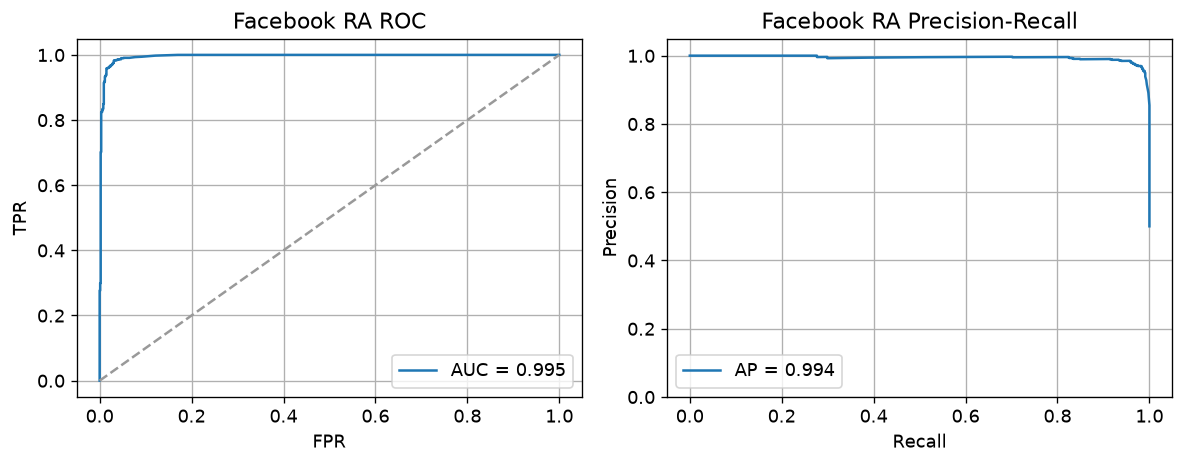

In [16]:
y_true_big = df_big["y"].values
summary_big = []
for k in KEYS + EXTRA:
    row = {"Heuristic": k}
    row.update(eval_binary_scores(y_true_big, df_big[k].values, ks=(10, 50, 100)))
    summary_big.append(row)
df_eval_big = pd.DataFrame(summary_big).sort_values("AUC", ascending=False).reset_index(drop=True)
display(df_eval_big)

pos_cn0 = (df_big.loc[df_big.y == 1, "CN"] == 0).mean()
neg_cn0 = (df_big.loc[df_big.y == 0, "CN"] == 0).mean()
print(f"Tỉ lệ cặp có CN = 0: dương {pos_cn0:.3f}, âm {neg_cn0:.3f}")

plot_big = df_eval_big[df_eval_big.Heuristic.isin(KEYS)]
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#F58518" if h in ("Katz", "PPR_sym", "HT_sim") else "#4C78A8" for h in plot_big.Heuristic]
ax.bar(plot_big.Heuristic, plot_big.AUC, color=colors)
ax.axhline(0.5, color="#999999", linestyle="--")
ax.set_ylim(0, 1.05)
ax.set_ylabel("ROC-AUC")
ax.set_title("ego-Facebook (1% held out): local (blue) vs global (orange)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(FIG / "facebook_auc_bar.png", bbox_inches="tight")
plt.show()

best_big = df_eval_big[df_eval_big.Heuristic.isin(KEYS)].iloc[0]["Heuristic"]
plot_roc_pr(y_true_big, df_big[best_big].values, title_prefix=f"Facebook {best_big}", fname="facebook_roc_pr_best.png")

## 1. Which heuristics performed best on the toy graph? Why?

### 1. Heuristic nào tốt nhất trên đồ thị nhỏ? Vì sao?

Lần chia chính (seed 42, 11 cặp dương + 11 cặp âm):

| Heuristic | AUC | AP | P@5 | P@10 |
| --- | --- | --- | --- | --- |
| PPR_sym | 0.975 | 0.975 | 1.0 | 0.9 |
| HT_sim | 0.901 | 0.929 | 1.0 | 0.9 |
| Katz | 0.893 | 0.903 | 1.0 | 0.8 |
| PA | 0.876 | 0.887 | 1.0 | 0.8 |
| AA, RA | 0.789 | 0.798 | 1.0 | 0.7 |
| HPI | 0.785 | 0.766 | 0.8 | 0.8 |
| CN | 0.752 | 0.715 | 0.4 | 0.7 |
| Salton | 0.715 | 0.655 | 0.6 | 0.8 |
| LHN1 | 0.698 | 0.632 | 0.6 | 0.7 |
| JC, Sørensen | 0.657 | 0.570 | 0.4 | 0.7 |
| HDI | 0.636 | 0.553 | 0.4 | 0.7 |

![AUC one split](figures/karate_auc_bar.png)

![PPR ROC/PR](figures/karate_roc_pr_PPR_sym.png)

Một lần chia chỉ có 22 cặp, nên không đủ để kết luận. Lần chia này còn lệch: 9 trong 11 cạnh bị giấu chạm vào hub 32 hoặc 33 (xem hình đỏ ở trên). Vì vậy PA (tích bậc) đứng thứ tư. Trung bình 30 lần chia đáng tin hơn:

| Heuristic | AUC (30 lần) | AP (30 lần) |
| --- | --- | --- |
| PPR_sym | **0.878 ± 0.066** | **0.886 ± 0.071** |
| Katz | 0.766 ± 0.085 | 0.782 ± 0.078 |
| RA | 0.747 ± 0.075 | 0.764 ± 0.072 |
| PA | 0.740 ± 0.068 | 0.747 ± 0.081 |
| AA | 0.737 ± 0.077 | 0.750 ± 0.069 |
| HT_sim | 0.708 ± 0.111 | 0.776 ± 0.093 |
| CN | 0.699 ± 0.079 | 0.690 ± 0.066 |
| HPI | 0.699 ± 0.094 | 0.666 ± 0.090 |
| Salton | 0.644 ± 0.099 | 0.623 ± 0.094 |
| Sørensen, JC | 0.615 ± 0.101 | 0.603 ± 0.082 |
| HDI | 0.601 ± 0.098 | 0.589 ± 0.074 |
| LHN1 | 0.599 ± 0.112 | 0.576 ± 0.090 |

![AUC 30 splits](figures/karate_auc_box.png)

PPR đối xứng tốt nhất, cách heuristic thứ hai hơn 0.1 AUC. Trong số local, RA, PA và AA đứng đầu.

Lý do chính: Karate thưa (bậc trung bình 4.6, sau khi giấu cạnh còn khoảng 3.9). Ở lần chia chính có 27% cặp dương **không có hàng xóm chung nào** trong đồ thị train, ví dụ (19, 33), (27, 33), (0, 31). Mọi heuristic dựa trên CN cho các cặp này điểm 0, bằng với 73% cặp âm cũng có CN = 0. Hai nhóm hòa nhau, AUC bị kéo xuống. PPR nhìn được đường đi dài hơn 2 bước, nên vẫn phân biệt được: cặp (19, 33) có PPR_sym 0.040, còn phần lớn cặp âm chỉ 0.004 đến 0.02. PPR còn tự chuẩn hóa theo bậc trên từng bước đi, nên không bị hub lấn át như Katz.

PA làm tốt vì cấu trúc của Karate: hai thủ lĩnh 0 và 33 nối với rất nhiều người, nên một cạnh ngẫu nhiên có xác suất cao chạm một trong hai hub. Cặp âm lấy ngẫu nhiên thì phần lớn là hai đỉnh bậc thấp.

## 2. Did degree-normalized indices (Salton/Sørensen/LHN1, etc.) beat raw CN?

### 2. Các chỉ số chuẩn hóa theo bậc có thắng CN thô không?

Không, trừ HPI. Đếm trên 30 lần chia (AUC):

| So với CN | Thắng | Hòa | Thua | AUC trung bình |
| --- | --- | --- | --- | --- |
| HPI ($/\min(k_x,k_y)$) | 18 | 0 | 12 | 0.699 (CN 0.699) |
| Salton | 6 | 1 | 23 | 0.644 |
| LHN1 | 3 | 1 | 26 | 0.599 |
| Sørensen | 1 | 0 | 29 | 0.615 |
| Jaccard | 1 | 0 | 29 | 0.615 |
| HDI ($/\max(k_x,k_y)$) | 1 | 0 | 29 | 0.601 |

Chuẩn hóa theo bậc phạt các cặp có một đầu là hub. Trên Karate, cạnh thật lại hay chạm hub. Ví dụ ở lần chia chính: cạnh thật (14, 33) có CN = 1 nhưng Jaccard chỉ 0.091, vì đỉnh 33 có nhiều hàng xóm. Cặp âm (13, 20) cũng CN = 1 nhưng Jaccard 0.200, vì cả hai đỉnh bậc thấp. Chuẩn hóa đảo ngược thứ tự đúng của hai cặp này. Chia càng mạnh cho bậc lớn (HDI chia cho max, LHN1 chia cho tích) thì càng tệ.

HPI là ngoại lệ vì chỉ chia cho bậc của đầu **nhỏ**. Cạnh (14, 33): trong đồ thị train đỉnh 14 chỉ còn bậc 1, nên HPI = 1/1 = 1.0, bằng điểm tối đa. HPI vì vậy không phạt hub, và hòa CN về trung bình.

Trên ego-Facebook (câu 6) thì khác: Salton, Jaccard, Sørensen, HDI có AUC 0.989 đến 0.992, gần bằng CN (0.993). Đồ thị đó dày và có nhiều cụm, nên số hàng xóm chung đã đủ mạnh, chuẩn hóa không làm hại nhiều. Chỉ LHN1 (chia cho tích bậc) tụt rõ, xuống 0.957.

## 3. Is RA better than AA here? Why?

### 3. RA có tốt hơn AA không? Vì sao?

Có, nhưng chỉ hơn một chút. Trên 30 lần chia, RA trung bình 0.747 so với AA 0.737. RA thắng 17 lần, hòa 11, thua 2. Ở lần chia chính hai cái bằng nhau (0.789). Trên Facebook RA 0.995, AA 0.994, RA đứng đầu toàn bảng.

Cả hai đều cộng điểm theo từng hàng xóm chung $z$ và giảm trọng số nếu $z$ có bậc cao. AA dùng $1/\log k_z$, RA dùng $1/k_z$, giảm mạnh hơn nhiều. Ví dụ: $z$ bậc 17 (đỉnh 33) được AA cho 0.35 điểm, RA chỉ cho 0.06. $z$ bậc 2 được AA cho 1.44, RA cho 0.5. Tỉ lệ giữa hai mức là 4 lần với AA, 8.5 lần với RA.

Ở Karate, hai hub 0 và 33 là hàng xóm chung của rất nhiều cặp, kể cả cặp ở hai phe khác nhau. Có chung hub là bằng chứng yếu. Có chung một đỉnh bậc thấp mới là dấu hiệu hai người cùng nhóm nhỏ. RA phạt hub mạnh hơn nên tận dụng điều này tốt hơn. Về mặt trực giác: mỗi đỉnh $z$ có một đơn vị "tài nguyên" chia đều cho $k_z$ hàng xóm, nên hub chuyển cho mỗi cặp rất ít.

11 lần hòa là những lần mọi cặp test có cùng thứ tự theo AA và RA, thường khi các cặp có điểm khác 0 chỉ có đúng một hàng xóm chung. Khi đó cả hai hàm đều giảm theo bậc nên thứ tự không đổi.

## 4. Are global methods (Katz/PPR/HT) worth their cost?

### 4. Các phương pháp global có đáng chi phí không?

Còn tùy đồ thị.

**Karate (thưa, nhỏ): đáng.** PPR_sym 0.878 so với local tốt nhất (RA) 0.747. Katz 0.766, chỉ hơn RA một chút. Hitting time 0.708 ± 0.111, không ổn định và không hơn CN. Thời gian không đáng kể vì ma trận chỉ 34 × 34.

Katz gần như không đổi theo β (0.005 → 0.766, 0.13 → 0.763). Mọi β đều nhỏ hơn $1/\rho \approx 0.16$, nên walk độ dài 2 (tức CN) vẫn chiếm phần lớn điểm. Walk dài hơn chủ yếu dùng để phá hòa giữa các cặp có CN = 0.

Hitting time $H_{u\to v}$ phụ thuộc mạnh vào bậc của đích: đi đến một hub thì nhanh, bất kể từ đâu. Nó gần giống PA hơn là một độ đo về "gần nhau". Commute time (đối xứng) còn tệ hơn trên Karate (0.681).

**ego-Facebook (4039 đỉnh, 88234 cạnh): không đáng.**

| Bước | Thời gian |
| --- | --- |
| 10 heuristic local cho 1764 cặp test | 0.28 s |
| Katz + PPR + HT (3 phép nghịch đảo ma trận 4039 × 4039) | 12.8 s |
| Riêng Katz / PPR / $L^+$ | 3.9 s / 3.3 s / 3.2 s |
| PPR_sym của **một** cặp bằng `nx.pagerank` | 0.24 s, nhân 1764 cặp khoảng 7 phút |

Global chậm hơn local khoảng 45 lần (hoặc khoảng 1500 lần nếu gọi `nx.pagerank` từng cặp như notebook mẫu), mà AUC không hơn: Katz 0.991, PPR 0.990, HT 0.857, so với RA 0.995.

Nghịch đảo ma trận dày tốn $O(n^3)$ thời gian và $O(n^2)$ bộ nhớ. 4039 đỉnh còn chạy được (130 MB mỗi ma trận). Một triệu đỉnh thì cần khoảng 8 TB, không làm được, phải chuyển sang Katz cắt ngắn bằng nhân ma trận thưa hoặc PPR xấp xỉ (push, Monte Carlo).

Kết luận: global đáng dùng khi đồ thị thưa và nhiều cạnh thật không có hàng xóm chung (Karate: 27% cặp dương có CN = 0). Khi đồ thị dày và nhiều cụm (Facebook: 0% cặp dương có CN = 0), heuristic local vừa rẻ vừa tốt hơn. Nếu phải chọn một phương pháp global, PPR ổn định nhất trong cả hai thí nghiệm.

## 5. For signs, which features mattered most (pp, pm, mp, mm, CN)?

### 5. Với dự đoán dấu, feature nào quan trọng nhất?

**Đồ thị nhỏ (12 đỉnh, 21 cạnh: 15 dương, 6 âm).**

![Toy signed graph](figures/signed_toy.png)

Trung bình feature theo dấu cạnh:

| Dấu | pp | pm | mp | mm | CN |
| --- | --- | --- | --- | --- | --- |
| −1 | 0 | 0 | 0 | 0 | 0 |
| +1 | 1.2 | 0 | 0 | 0 | 1.2 |

Cả 6 cạnh âm đều là cầu nối giữa hai cụm, không nằm trong tam giác nào, nên mọi feature đều bằng 0. Cạnh dương nằm trong các cụm 4 đỉnh dày, nên có hàng xóm chung kiểu ++. pm, mp, mm luôn bằng 0, và pp trùng hệ với CN.

Mô hình học trọng số pp = 0.767, CN = 0.767, pm = mp = mm = 0. Nói cách khác, chỉ có pp/CN mang thông tin: cạnh nằm trong tam giác ++ thì dương. Leave-one-out trên 21 cạnh đạt accuracy 1.000. Lần chia 70/30 chỉ đạt 0.714 (F1 0.833, AUC 0.800). Lý do: hai cạnh dương (2, 3) và (3, 4) cùng rơi vào test, nên trong đồ thị train chúng mất tam giác và có feature bằng 0, giống hệt cạnh âm. Mô hình đoán mọi cặp có feature 0 là dương (lớp đa số, P(+) = 0.596), nên sai cả hai cạnh âm (4, 7) và (3, 11). Đồ thị quá nhỏ: chỉ cần giấu vài cạnh là cấu trúc tam giác biến mất.

**Đồ thị có dấu tổng hợp (100 đỉnh, 687 cạnh, 56% dương).** Ở đây đủ bốn kiểu tam giác, nên thấy rõ vai trò từng feature.

| Feature | Hệ số (đã chuẩn hóa) | AUC khi chỉ dùng feature này |
| --- | --- | --- |
| pp | **+1.158** | **0.750** |
| pm | −0.625 | 0.565 |
| mp | −0.610 | 0.552 |
| mm | +0.280 | 0.518 |
| CN | +0.535 | 0.643 |

![Signed weights](figures/signed_sbm_weights.png)

Logistic regression: accuracy 0.729, F1 0.745, AUC 0.763. Luật cân bằng thuần (đếm phiếu ++ và −− trừ +− và −+) đạt 0.633, đoán toàn dương đạt 0.560.

Dấu của hệ số khớp lý thuyết cân bằng cấu trúc: bạn của bạn là bạn (pp dương), bạn của kẻ thù là kẻ thù (pm, mp âm), kẻ thù của kẻ thù là bạn (mm dương). **pp quan trọng nhất**: một mình nó đạt AUC 0.750, gần bằng cả mô hình (0.763). pm và mp gần như đối xứng, đúng vì đồ thị vô hướng. mm yếu nhất: một mình nó chỉ đạt 0.518. Trong đồ thị này, cặp $u, v$ có kẻ thù chung $z$ có thể cùng nhóm (cạnh +), nhưng cũng có thể thuộc hai nhóm khác nhau và $z$ ở nhóm thứ ba (cạnh −). "Kẻ thù của kẻ thù" vì vậy không chắc là bạn. Bỏ riêng một feature nào thì AUC hầu như không đổi (0.763 đến 0.770), vì CN là tổng của bốn feature kia, nên các feature dư thừa lẫn nhau.

## 6. (Optional) Run and analyze on a larger graph.

### 6. (Tùy chọn) Chạy và phân tích trên đồ thị lớn.

ego-Facebook, giấu 882 cạnh (1%), đồ thị train vẫn liên thông, 882 cặp âm.

| Heuristic | AUC | AP | P@10 | P@50 | P@100 |
| --- | --- | --- | --- | --- | --- |
| RA | **0.995** | **0.994** | 1.0 | 1.00 | 1.00 |
| AA | 0.994 | 0.990 | 1.0 | 1.00 | 1.00 |
| CN | 0.993 | 0.988 | 1.0 | 1.00 | 1.00 |
| Salton | 0.992 | 0.990 | 1.0 | 1.00 | 1.00 |
| Katz | 0.991 | 0.987 | 1.0 | 1.00 | 1.00 |
| JC, Sørensen | 0.990 | 0.988 | 1.0 | 1.00 | 1.00 |
| PPR_sym | 0.990 | 0.984 | 1.0 | 1.00 | 1.00 |
| HPI | 0.989 | 0.978 | 0.7 | 0.94 | 0.97 |
| HDI | 0.989 | 0.986 | 1.0 | 1.00 | 1.00 |
| LHN1 | 0.957 | 0.907 | 0.8 | 0.86 | 0.85 |
| CT_sim | 0.914 | 0.922 | 1.0 | 1.00 | 1.00 |
| HT_sim | 0.857 | 0.870 | 1.0 | 1.00 | 1.00 |
| PA | 0.841 | 0.857 | 1.0 | 0.96 | 0.98 |

![Facebook AUC](figures/facebook_auc_bar.png)

![Facebook RA](figures/facebook_roc_pr_best.png)

Kết luận khác hẳn Karate, đúng như notebook mẫu cảnh báo:

- **Local thắng global.** Không cặp dương nào có CN = 0, trong khi 83% cặp âm có CN = 0. Chỉ cần hỏi "có bạn chung không" là đã tách gần hết hai lớp. ego-Facebook gồm các nhóm bạn rất dày (hệ số clustering khoảng 0.6), nên hầu như cạnh nào cũng nằm trong tam giác. Global không có gì để bù thêm, mà chậm hơn khoảng 45 lần (câu 4).
- **RA vẫn hơn AA**, và đứng đầu. Trong đồ thị này hub có bậc tới 1045, nên giảm mạnh trọng số của hàng xóm chung là hub vẫn có lợi.
- **Chuẩn hóa theo bậc không còn gây hại** (Salton, Jaccard, Sørensen, HDI cách CN chưa tới 0.004 AUC). Chỉ LHN1 và HPI tụt ở Precision@k. HPI cho điểm tối đa mỗi khi một đầu có bậc nhỏ, nên các cặp đầu bảng bị nhiễu (P@10 = 0.7).
- **PA tụt từ một trong những cái tốt nhất (Karate) xuống cuối bảng** (0.841). Facebook có nhiều cụm bạn bè quanh các ego, nên hai hub ở hai cụm khác nhau thường không quen nhau. Cấu trúc quanh hai thủ lĩnh của Karate không còn.
- Hitting time vẫn kém (0.857) vì lý do như ở Karate: bị bậc của đích chi phối.